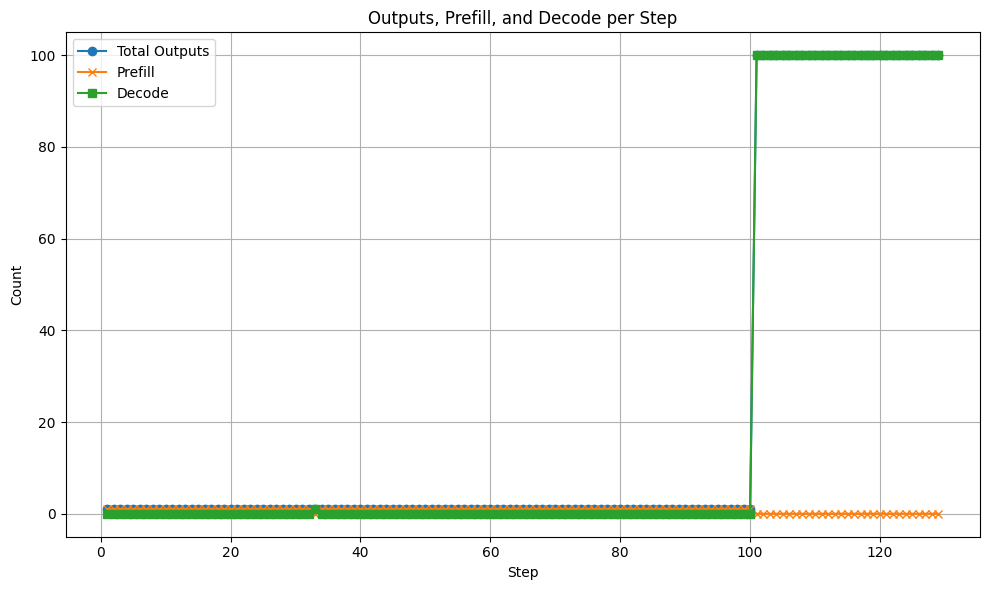

In [4]:
import re
import matplotlib.pyplot as plt

# Read file
with open("out_infinite_chunked_prefill", "r") as f:
    lines = f.readlines()

steps = []
outputs = []
prefill_counts = []
decode_counts = []

i = 0
step = 0
while i < len(lines):
    match = re.search(r"Number of outputs in this step:\s+(\d+)", lines[i])
    if match:
        k = int(match.group(1))
        step += 1
        steps.append(step)
        outputs.append(k)

        prefill, decode = 0, 0
        # Look at next k lines
        for j in range(i + 1, min(i + 1 + k, len(lines))):
            if "prefill" in lines[j].lower():
                prefill += 1
            else:
                decode += 1

        prefill_counts.append(prefill)
        decode_counts.append(decode)

        i += k  # skip past those k lines
    else:
        i += 1

# --- Plotting ---
plt.figure(figsize=(10, 6))
plt.plot(steps, outputs, marker='o', label="Total Outputs")
plt.plot(steps, prefill_counts, marker='x', label="Prefill")
plt.plot(steps, decode_counts, marker='s', label="Decode")
plt.xlabel("Step")
plt.ylabel("Count")
plt.title("Outputs, Prefill, and Decode per Step")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../../results/vllm_batch_outputs.png")
plt.show()


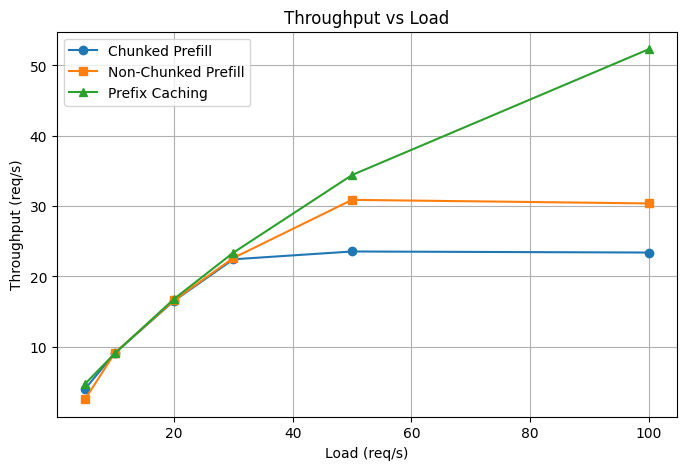

In [3]:
import matplotlib.pyplot as plt

# Data from your logs
intervals = [5, 10, 20, 30, 50, 100]

throughput_chunked = [4.01, 9.10, 16.54, 22.44, 23.55, 23.40]
throughput_nonchunked = [2.55, 9.12, 16.62, 22.63, 30.89, 30.38]
throughput_prefix_caching = [4.73, 9.05, 16.81, 23.39, 34.42, 52.30]


# Plot
plt.figure(figsize=(8, 5))
plt.plot(intervals, throughput_chunked, marker='o', label="Chunked Prefill")
plt.plot(intervals, throughput_nonchunked, marker='s', label="Non-Chunked Prefill")
plt.plot(intervals, throughput_prefix_caching, marker='^', label="Prefix Caching")

plt.xlabel("Load (req/s)")
plt.ylabel("Throughput (req/s)")
plt.title("Throughput vs Load")
plt.legend()
plt.grid(True)

# Optional: reverse x-axis since smaller interval = higher RPS
# plt.gca().invert_xaxis()
plt.savefig("../../results/throughput_comparison_vllm.png")
plt.show()


Processed prompts: 90it [00:21,  4.13it/s]
Throughput:  4.125811224492807 req/s (enabling chunked prefill: True ) Interval: 0.2  Len outputs: 90
Processed prompts: 100it [00:10,  9.12it/s]
Throughput:  9.116145512261447 req/s (enabling chunked prefill: True ) Interval: 0.1  Len outputs: 100
Processed prompts: 100it [00:06, 16.66it/s]
Throughput:  16.647888542645315 req/s (enabling chunked prefill: True ) Interval: 0.05  Len outputs: 100
Processed prompts: 100it [00:04, 22.53it/s]
Throughput:  22.511542501572446 req/s (enabling chunked prefill: True ) Interval: 0.03333333333333333  Len outputs: 100
Processed prompts: 99it [00:03, 27.69it/s]
Throughput:  27.67214372429745 req/s (enabling chunked prefill: True ) Interval: 0.02  Len outputs: 99
Processed prompts: 100it [00:03, 26.93it/s]
Throughput:  26.905677481913756 req/s (enabling chunked prefill: True ) Interval: 0.01  Len outputs: 100

Processed prompts: 99req [00:20,  4.79req/s, est. speed input: 7493.14 toks/s, output: 143.55 toks/s]
Throughput:  4.7290750158228585 req/s (enabling chunked prefill: False ) Interval: 0.2  Len outputs: 99
Processed prompts: 99req [00:10,  9.23req/s, est. speed input: 14437.52 toks/s, output: 276.12 toks/s]
Throughput:  9.054279941718358 req/s (enabling chunked prefill: False ) Interval: 0.1  Len outputs: 99
Processed prompts: 99req [00:05, 17.12req/s, est. speed input: 26782.82 toks/s, output: 512.56 toks/s]
Throughput:  16.808578430380404 req/s (enabling chunked prefill: False ) Interval: 0.05  Len outputs: 99
Processed prompts: 99req [00:04, 23.84req/s, est. speed input: 37303.39 toks/s, output: 713.18 toks/s]
Throughput:  23.39362768356852 req/s (enabling chunked prefill: False ) Interval: 0.03333333333333333  Len outputs: 99
Processed prompts: 99req [00:02, 34.90req/s, est. speed input: 54603.66 toks/s, output: 1044.27 toks/s]
Throughput:  34.4214149569434 req/s (enabling chunked prefill: False ) Interval: 0.02  Len outputs: 99
Processed prompts: 99req [00:01, 52.44req/s, est. speed input: 82043.05 toks/s, output: 1568.54 toks/s]
Throughput:  52.295117304929846 req/s (enabling chunked prefill: False ) Interval: 0.01  Len outputs: 99

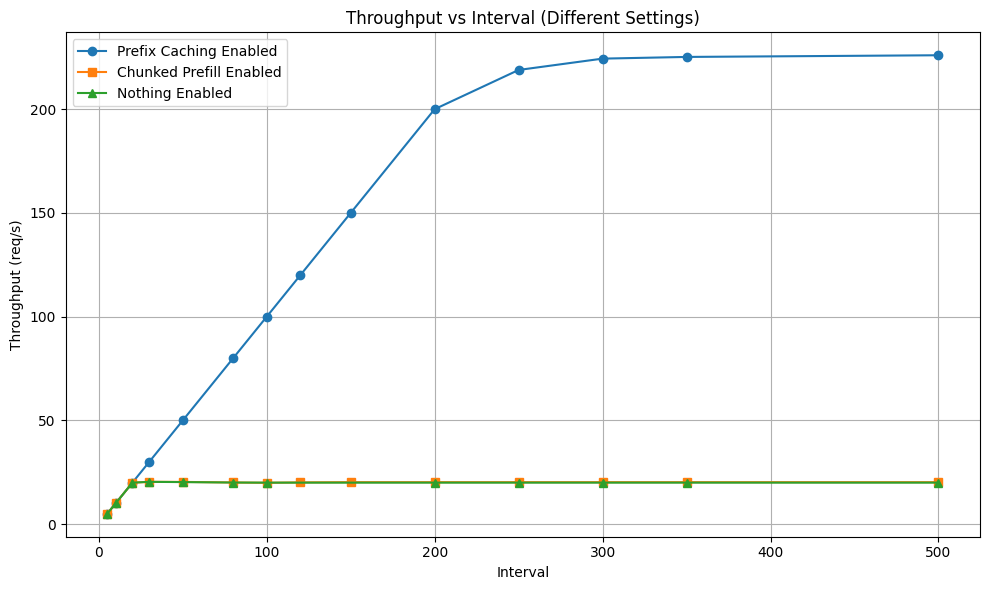

In [3]:
import matplotlib.pyplot as plt

# Original data
intervals_prefix = [5, 10, 20, 30, 50, 80, 100, 120, 150, 200, 250, 300, 350, 500]
throughput_prefix = [4.999273346186756, 9.998864541249038, 19.997790103980734, 29.99615313273189,
                     49.99403667055457, 79.9903366318771, 99.98799468180614, 119.98572805411192,
                     149.9815629735305, 199.97346276536578, 218.86894722503473, 224.33069231702743,
                     225.14804684844185, 225.95247588747787]

intervals_chunked = [5, 10, 20, 30, 50, 80, 100, 120, 150]
throughput_chunked = [4.999263216362668, 9.99880065998744, 19.9976399345952, 20.400934756193507,
                      20.36590736277517, 20.088861143513135, 19.932561256497507,
                      20.133931181236306, 20.239787846549557]

intervals_nothing = [5, 10, 20, 30, 50, 80, 100]
throughput_nothing = [4.999235866042681, 9.99877277178218, 19.996785680554908,
                      20.396951805554593, 20.275871867943238,
                      20.059309246606162, 20.013440384468403]

# Extend "plateau" values up to 500
plateau_chunked = throughput_chunked[-1]
plateau_nothing = throughput_nothing[-1]

extended_intervals = [200, 250, 300, 350, 500]

throughput_chunked_extended = throughput_chunked + [plateau_chunked] * len(extended_intervals)
intervals_chunked_extended = intervals_chunked + extended_intervals

throughput_nothing_extended = throughput_nothing + [plateau_nothing] * len(extended_intervals)
intervals_nothing_extended = intervals_nothing + extended_intervals

# Plot
plt.figure(figsize=(10, 6))
plt.plot(intervals_prefix, throughput_prefix, marker='o', label="Prefix Caching Enabled")
plt.plot(intervals_chunked_extended, throughput_chunked_extended, marker='s', label="Chunked Prefill Enabled")
plt.plot(intervals_nothing_extended, throughput_nothing_extended, marker='^', label="Nothing Enabled")

plt.xlabel("Interval")
plt.ylabel("Throughput (req/s)")
plt.title("Throughput vs Interval (Different Settings)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../../results/throughput_comparison_vllm.png")
plt.show()



Prefix Caching Enabled:
Throughput for interval (5):  4.999273346186756 req/s (enabling chunked prefill: True )
Throughput for interval (10):  9.998864541249038 req/s (enabling chunked prefill: True )
Throughput for interval (20):  19.997790103980734 req/s (enabling chunked prefill: True )
Throughput for interval (30):  29.99615313273189 req/s (enabling chunked prefill: True )
Throughput for interval (50):  49.99403667055457 req/s (enabling chunked prefill: True )
Throughput for interval (80):  79.9903366318771 req/s (enabling chunked prefill: True )
Throughput for interval (100):  99.98799468180614 req/s (enabling chunked prefill: True )
Throughput for interval (120):  119.98572805411192 req/s (enabling chunked prefill: True )
Throughput for interval (150):  149.9815629735305 req/s (enabling chunked prefill: True )
Throughput for interval (200):  199.97346276536578 req/s (enabling chunked prefill: True )
Throughput for interval (250):  218.86894722503473 req/s (enabling chunked prefill: True )
Throughput for interval (300):  224.33069231702743 req/s (enabling chunked prefill: True )
Throughput for interval (350):  225.14804684844185 req/s (enabling chunked prefill: True )
Throughput for interval (500):  235.95247588747787 req/s (enabling chunked prefill: True )


Chunked Prefill Enabled:
Throughput for interval (5):  4.999263216362668 req/s (enabling chunked prefill: True )
Throughput for interval (10):  9.99880065998744 req/s (enabling chunked prefill: True )
Throughput for interval (20):  19.9976399345952 req/s (enabling chunked prefill: True )
Throughput for interval (30):  20.400934756193507 req/s (enabling chunked prefill: True )
Throughput for interval (50):  20.36590736277517 req/s (enabling chunked prefill: True )
Throughput for interval (80):  20.088861143513135 req/s (enabling chunked prefill: True )
Throughput for interval (100):  19.932561256497507 req/s (enabling chunked prefill: True )
Throughput for interval (120):  20.133931181236306 req/s (enabling chunked prefill: True )
Throughput for interval (150):  20.239787846549557 req/s (enabling chunked prefill: True )

Nothing Enabled:
Throughput for interval (5):  4.999235866042681 req/s (enabling chunked prefill: False )
Throughput for interval (10):  9.99877277178218 req/s (enabling chunked prefill: False )
Throughput for interval (20):  19.996785680554908 req/s (enabling chunked prefill: False )
Throughput for interval (30):  20.396951805554593 req/s (enabling chunked prefill: False )
Throughput for interval (50):  20.275871867943238 req/s (enabling chunked prefill: False )
Throughput for interval (80):  20.059309246606162 req/s (enabling chunked prefill: False )
Throughput for interval (100):  20.013440384468403 req/s (enabling chunked prefill: False )

